# EN3150 Assignment 03
## Resource-Constrained CNN for Fashion-MNIST

We compare a standard CNN, a lightweight CNN, MobileNetV2 and EfficientNetB0 using Fashion-MNIST.

1. Load and inspect the dataset
2. Create the 70/15/15 split and preprocess the images
3. Build Model A and Model B and calculate their parameters
4. Compare optimizers using validation performance
5. Train and evaluate the custom models
6. Fine-tune and evaluate the pretrained models
7. Compare accuracy, storage, training time and computational cost

The notebook was executed with Python 3.13.15 and TensorFlow 2.21.0.

## 1. Import Libraries

We first import the libraries needed for the project.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

import random
import platform
SEED = 42
EPOCHS = 20
BATCH_SIZE = 128

def reset_randomness():
    random.seed(SEED)
    np.random.seed(SEED)
    keras.utils.set_random_seed(SEED)

reset_randomness()
tf.config.experimental.enable_op_determinism()
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

class EpochTimer(keras.callbacks.Callback):
    # Full fit epoch includes validation and first-epoch setup.
    def on_train_begin(self, logs=None):
        self.seconds = []
    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.perf_counter() - self.started)

Python: 3.13.15 TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Fashion-MNIST

Fashion-MNIST has 70,000 grayscale clothing images.

Each image is $28 \times 28$ pixels, so it is already smaller than the assignment limit of $64 \times 64$ pixels.

In [2]:
(x1, y1), (x2, y2) = keras.datasets.fashion_mnist.load_data()

# Combine the original train and test sets.
# We do this because our assignment needs a new 70/15/15 split.

images = np.concatenate((x1, x2))
labels = np.concatenate((y1, y2))

print("Images:", images.shape)
print("Labels:", labels.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Images: (70000, 28, 28)
Labels: (70000,)


## 3. Class Names

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

## 4. View Some Images

Before training, we look at a few samples from the dataset.

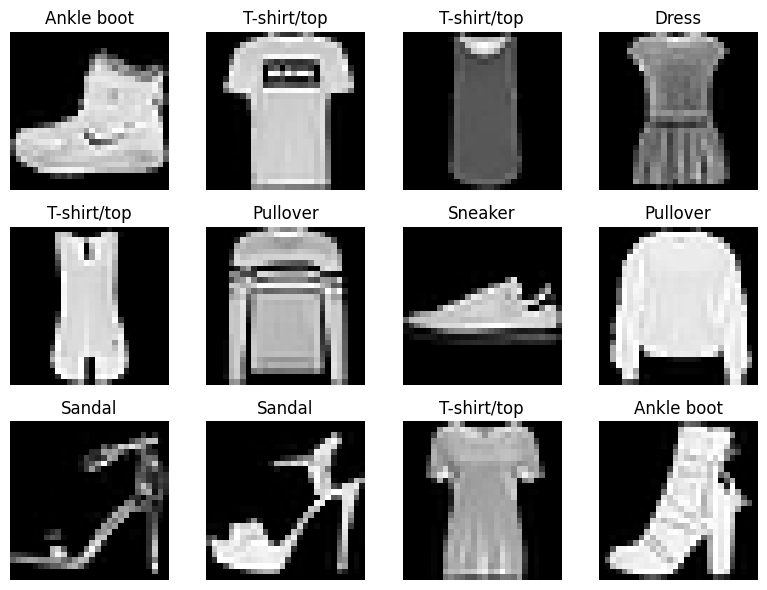

In [4]:
plt.figure(figsize=(8, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Check Class Distribution

Fashion-MNIST is a balanced dataset.  
We check how many images belong to each class.

In [5]:
counts = np.bincount(labels)

for i in range(10):
    print(i, class_names[i], ":", counts[i])

0 T-shirt/top : 7000
1 Trouser : 7000
2 Pullover : 7000
3 Dress : 7000
4 Coat : 7000
5 Sandal : 7000
6 Shirt : 7000
7 Sneaker : 7000
8 Bag : 7000
9 Ankle boot : 7000


## 6. Split the Data

The assignment requires:

- 70% training
- 15% validation
- 15% testing

We use `stratify=labels` so all sets keep approximately the same class distribution.

In [6]:
x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    images,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", x_train_raw.shape)
print("Validation:", x_val_raw.shape)
print("Testing:", x_test_raw.shape)

Training: (49000, 28, 28)
Validation: (10500, 28, 28)
Testing: (10500, 28, 28)


## 7. Data Preprocessing

For Model A and Model B, we divide pixel values by 255 and add a channel dimension. The inputs are normalized $28 \times 28$ grayscale images with shape $28 \times 28 \times 1$.

In [7]:
x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_val = np.expand_dims(x_val, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training: (49000, 28, 28, 1)
Validation: (10500, 28, 28, 1)
Testing: (10500, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# Model A - Standard CNN

## 8. Build Model A

Model A uses two standard $3 \times 3$ Conv2D layers with 16 and 32 filters, each followed by max pooling. Flattened features pass through Dense 64 and the ten-class output layer.

ReLU is inexpensive for inference. Softmax is limited to the ten-class output layer.

In [8]:
model_a = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Calculate Parameters of Model A

For a normal convolution layer:

$$
\text{Parameters} =
(K_h K_w C_{\mathrm{in}}+1)C_{\mathrm{out}}
$$

### Conv2D 1

$$
(3\times3\times1+1)\times16 = 160
$$

### Conv2D 2

$$
(3\times3\times16+1)\times32 = 4,640
$$

After the two pooling layers:

$$
28\times28 \rightarrow 14\times14 \rightarrow 7\times7
$$

So Flatten gives:

$$
7\times7\times32 = 1568
$$

### Dense 64

$$
(1568+1)\times64 = 100,416
$$

### Output Layer

$$
(64+1)\times10 = 650
$$

### Total

$$
160+4640+100416+650 = 105,866
$$

In [9]:
print("Model A parameters:", model_a.count_params())

Model A parameters: 105866


# Model B - Lightweight CNN

## 10. Build Model B

Model B uses three $3 \times 3$ SeparableConv2D layers with 16, 32 and 64 filters. Global average pooling is followed by Dense 32 and Dense 10.

Depthwise convolution applies a spatial filter to each input channel. A $1 \times 1$ pointwise convolution combines the channels. With depth multiplier 1, the weight count changes from $K_h \times K_w \times C_{\mathrm{in}} \times C_{\mathrm{out}}$ to $K_h \times K_w \times C_{\mathrm{in}} + C_{\mathrm{in}} \times C_{\mathrm{out}}$.

Global average pooling and the smaller dense head also contribute to Model B's resource savings.

In [10]:
model_b = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.SeparableConv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(64, (3, 3), padding="same", activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_b.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 28, 28, 16)     │            41 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 14, 14, 32)     │           688 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 7, 7, 64)       │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,539 (21.64 KB)

 Trainable params: 5,539 (21.64 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Calculate Parameters of Model B

With depth multiplier 1 and an output bias:

$$
\text{Parameters} = K_h \times K_w \times C_{\mathrm{in}} + C_{\mathrm{in}} \times C_{\mathrm{out}} + C_{\mathrm{out}}
$$

- Separable $3 \times 3$, $1 \rightarrow 16$: $9 + 16 + 16 = 41$
- Separable $3 \times 3$, $16 \rightarrow 32$: $144 + 512 + 32 = 688$
- Separable $3 \times 3$, $32 \rightarrow 64$: $288 + 2048 + 64 = 2400$
- Global average pooling: 0
- Dense $64 \rightarrow 32$: $(64 + 1) \times 32 = 2080$
- Dense $32 \rightarrow 10$: $(32 + 1) \times 10 = 330$

**Total: 5,539 trainable parameters**, below the assignment limit of 100,000.

ReLU is inexpensive for inference; Softmax is limited to the ten-class output.

In [11]:
assert model_a.count_params() == 105866
assert model_b.count_params() == 5539
assert sum(int(np.prod(w.shape)) for w in model_b.trainable_weights) <= 100000
print("Model B parameters:", model_b.count_params())
initial_b_weights = [w.copy() for w in model_b.get_weights()]
optimizer_histories = {}
optimizer_models = {}
optimizer_timers = {}

def make_optimizer(name):
    if name == "Adam":
        return keras.optimizers.Adam(learning_rate=0.001)
    if name == "SGD":
        return keras.optimizers.SGD(learning_rate=0.01)
    if name == "SGD + Momentum":
        return keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    raise ValueError(name)

def custom_training_data():
    return (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(len(y_train), seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

def compare_optimizer(name):
    reset_randomness()
    candidate = keras.models.clone_model(model_b)
    candidate.set_weights(initial_b_weights)
    candidate.compile(optimizer=make_optimizer(name),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    timer = EpochTimer()
    history = candidate.fit(custom_training_data(), validation_data=(x_val, y_val),
                            epochs=EPOCHS, callbacks=[timer], verbose=2)
    optimizer_models[name] = candidate
    optimizer_histories[name] = history
    optimizer_timers[name] = timer
    return candidate, history

Model B parameters: 5539


# Optimizer Comparison

## 12. Adam

We compare Adam (learning rate 0.001), SGD (0.01), and SGD with Momentum (0.01, momentum 0.9).

All three use identical initial weights, controlled data ordering, the same split and batch size, and 20 epochs. We select using final validation loss. These are fixed configurations, without exhaustive learning-rate tuning.

In [12]:
adam_model, adam_history = compare_optimizer("Adam")

Epoch 1/20
383/383 - 10s - 27ms/step - accuracy: 0.3591 - loss: 1.7113 - val_accuracy: 0.4903 - val_loss: 1.2386
Epoch 2/20
383/383 - 4s - 10ms/step - accuracy: 0.5781 - loss: 1.0931 - val_accuracy: 0.6261 - val_loss: 0.9987
Epoch 3/20
383/383 - 4s - 10ms/step - accuracy: 0.6617 - loss: 0.9234 - val_accuracy: 0.6956 - val_loss: 0.8613
Epoch 4/20
383/383 - 4s - 10ms/step - accuracy: 0.6958 - loss: 0.8406 - val_accuracy: 0.7029 - val_loss: 0.8277
Epoch 5/20
383/383 - 4s - 10ms/step - accuracy: 0.7151 - loss: 0.7861 - val_accuracy: 0.7269 - val_loss: 0.7764
Epoch 6/20
383/383 - 4s - 10ms/step - accuracy: 0.7271 - loss: 0.7505 - val_accuracy: 0.7334 - val_loss: 0.7431
Epoch 7/20
383/383 - 4s - 10ms/step - accuracy: 0.7406 - loss: 0.7181 - val_accuracy: 0.7482 - val_loss: 0.7027
Epoch 8/20
383/383 - 4s - 10ms/step - accuracy: 0.7441 - loss: 0.6966 - val_accuracy: 0.7386 - val_loss: 0.6947
Epoch 9/20
383/383 - 4s - 10ms/step - accuracy: 0.7516 - loss: 0.6796 - val_accuracy: 0.7585 - val_loss

## 13. Standard SGD

Now we use normal Stochastic Gradient Descent.

Learning rate = 0.01

In [13]:
sgd_model, sgd_history = compare_optimizer("SGD")

Epoch 1/20
383/383 - 4s - 11ms/step - accuracy: 0.1161 - loss: 2.3022 - val_accuracy: 0.1000 - val_loss: 2.3021
Epoch 2/20
383/383 - 3s - 9ms/step - accuracy: 0.1135 - loss: 2.3021 - val_accuracy: 0.1021 - val_loss: 2.3020
Epoch 3/20
383/383 - 3s - 8ms/step - accuracy: 0.1229 - loss: 2.3019 - val_accuracy: 0.1000 - val_loss: 2.3019
Epoch 4/20
383/383 - 3s - 9ms/step - accuracy: 0.1399 - loss: 2.3019 - val_accuracy: 0.1117 - val_loss: 2.3018
Epoch 5/20
383/383 - 4s - 11ms/step - accuracy: 0.1369 - loss: 2.3018 - val_accuracy: 0.1554 - val_loss: 2.3016
Epoch 6/20
383/383 - 4s - 11ms/step - accuracy: 0.1373 - loss: 2.3016 - val_accuracy: 0.2355 - val_loss: 2.3015
Epoch 7/20
383/383 - 5s - 14ms/step - accuracy: 0.1560 - loss: 2.3015 - val_accuracy: 0.1742 - val_loss: 2.3013
Epoch 8/20
383/383 - 3s - 9ms/step - accuracy: 0.1567 - loss: 2.3013 - val_accuracy: 0.1563 - val_loss: 2.3011
Epoch 9/20
383/383 - 3s - 9ms/step - accuracy: 0.1750 - loss: 2.3010 - val_accuracy: 0.2562 - val_loss: 2.30

## 14. SGD with Momentum

We use learning rate 0.01 and momentum 0.9. Momentum carries part of the previous update forward, which can reduce zig-zag movement and speed up convergence.

Here, it gives lower final validation loss than plain SGD. This improvement applies to the tested settings; momentum does not always improve performance.

In [14]:
momentum_model, momentum_history = compare_optimizer("SGD + Momentum")

Epoch 1/20
383/383 - 5s - 12ms/step - accuracy: 0.1046 - loss: 2.3019 - val_accuracy: 0.1000 - val_loss: 2.3010
Epoch 2/20
383/383 - 7s - 19ms/step - accuracy: 0.1412 - loss: 2.2835 - val_accuracy: 0.1913 - val_loss: 2.1929
Epoch 3/20
383/383 - 7s - 19ms/step - accuracy: 0.3607 - loss: 1.6583 - val_accuracy: 0.5170 - val_loss: 1.0989
Epoch 4/20
383/383 - 3s - 9ms/step - accuracy: 0.6125 - loss: 0.9854 - val_accuracy: 0.6205 - val_loss: 0.9241
Epoch 5/20
383/383 - 3s - 9ms/step - accuracy: 0.6627 - loss: 0.8654 - val_accuracy: 0.6588 - val_loss: 0.8560
Epoch 6/20
383/383 - 3s - 9ms/step - accuracy: 0.6780 - loss: 0.8295 - val_accuracy: 0.6881 - val_loss: 0.8254
Epoch 7/20
383/383 - 4s - 9ms/step - accuracy: 0.7019 - loss: 0.7775 - val_accuracy: 0.7158 - val_loss: 0.7666
Epoch 8/20
383/383 - 3s - 9ms/step - accuracy: 0.7157 - loss: 0.7419 - val_accuracy: 0.7285 - val_loss: 0.7347
Epoch 9/20
383/383 - 3s - 9ms/step - accuracy: 0.7269 - loss: 0.7158 - val_accuracy: 0.7255 - val_loss: 0.698

## 15. Compare Optimizer Validation Loss

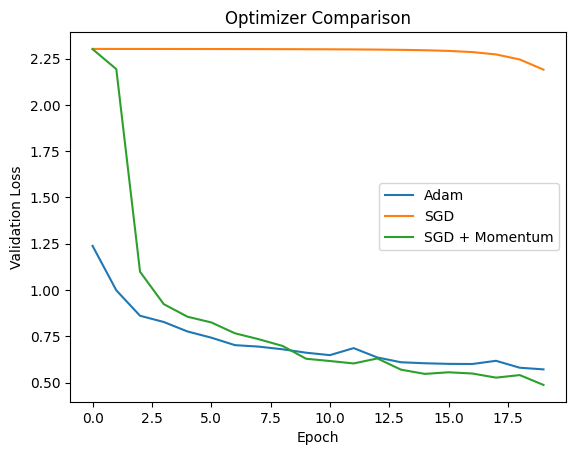

In [15]:
plt.plot(adam_history.history["val_loss"], label="Adam")
plt.plot(sgd_history.history["val_loss"], label="SGD")
plt.plot(momentum_history.history["val_loss"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 16. Compare Optimizer Validation Accuracy

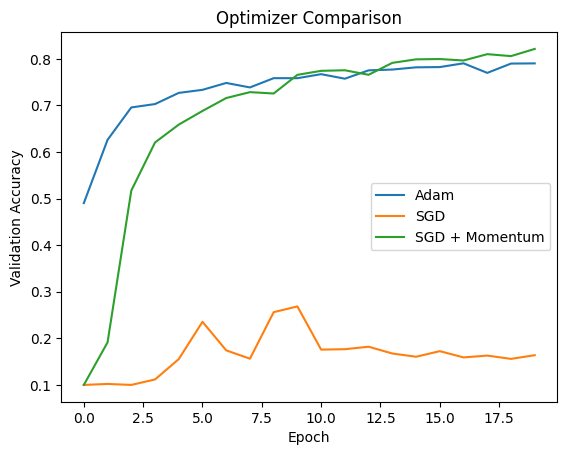

In [16]:
plt.plot(adam_history.history["val_accuracy"], label="Adam")
plt.plot(sgd_history.history["val_accuracy"], label="SGD")
plt.plot(momentum_history.history["val_accuracy"], label="SGD + Momentum")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Optimizer Comparison")
plt.legend()
plt.show()

## 17. Select Using Validation Only

Final validation losses are 0.571803 for Adam, 2.190192 for SGD and 0.487881 for SGD with Momentum.

SGD with Momentum has the lowest loss, so we select it for the main custom-model comparison. Test accuracy is not used for this decision.

In [17]:
optimizer_results = pd.DataFrame([
    {"Optimizer": name, "Final Validation Loss": h.history["val_loss"][-1],
     "Final Validation Accuracy": h.history["val_accuracy"][-1]}
    for name, h in optimizer_histories.items()
])
selected_optimizer = optimizer_results.loc[
    optimizer_results["Final Validation Loss"].idxmin(), "Optimizer"]
print("Selected using validation loss:", selected_optimizer)
optimizer_results

Selected using validation loss: SGD + Momentum


,Optimizer,Final Validation Loss,Final Validation Accuracy
0,Adam,0.571803,0.790190
1,SGD,2.190192,0.163810
2,SGD + Momentum,0.487881,0.821238


# Train Model A and Model B

## 18. Train Model A

Model A uses the selected SGD optimizer with learning rate 0.01 and momentum 0.9. Both custom models train for 20 epochs with batch size 128.

Average training time per epoch includes validation and initial startup overhead.

In [18]:
reset_randomness()
model_a.compile(optimizer=make_optimizer(selected_optimizer),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_a = EpochTimer()
history_a = model_a.fit(custom_training_data(), validation_data=(x_val, y_val),
                        epochs=EPOCHS, callbacks=[timer_a], verbose=2)
time_per_epoch_a = float(np.mean(timer_a.seconds))
print("Average fit time per epoch:", time_per_epoch_a, "seconds")

Epoch 1/20
383/383 - 5s - 12ms/step - accuracy: 0.7311 - loss: 0.7463 - val_accuracy: 0.8277 - val_loss: 0.4811
Epoch 2/20
383/383 - 3s - 9ms/step - accuracy: 0.8441 - loss: 0.4328 - val_accuracy: 0.8537 - val_loss: 0.4024
Epoch 3/20
383/383 - 3s - 8ms/step - accuracy: 0.8665 - loss: 0.3690 - val_accuracy: 0.8774 - val_loss: 0.3467
Epoch 4/20
383/383 - 3s - 9ms/step - accuracy: 0.8787 - loss: 0.3372 - val_accuracy: 0.8726 - val_loss: 0.3466
Epoch 5/20
383/383 - 3s - 8ms/step - accuracy: 0.8889 - loss: 0.3095 - val_accuracy: 0.8943 - val_loss: 0.3070
Epoch 6/20
383/383 - 4s - 11ms/step - accuracy: 0.8926 - loss: 0.2941 - val_accuracy: 0.8960 - val_loss: 0.2964
Epoch 7/20
383/383 - 3s - 9ms/step - accuracy: 0.8998 - loss: 0.2769 - val_accuracy: 0.8993 - val_loss: 0.2917
Epoch 8/20
383/383 - 3s - 8ms/step - accuracy: 0.9014 - loss: 0.2701 - val_accuracy: 0.8997 - val_loss: 0.2849
Epoch 9/20
383/383 - 3s - 8ms/step - accuracy: 0.9081 - loss: 0.2514 - val_accuracy: 0.9019 - val_loss: 0.2766

## 19. Reuse the Selected Model B Run

We use the SGD with Momentum version of Model B from the optimizer comparison. Its training history, timing and test evaluation all use the same 20-epoch run.

In [19]:
model_b = optimizer_models[selected_optimizer]
history_b = optimizer_histories[selected_optimizer]
time_per_epoch_b = float(np.mean(optimizer_timers[selected_optimizer].seconds))
assert len(history_a.history["loss"]) >= 20
assert len(history_b.history["loss"]) >= 20
print("Average fit time per epoch:", time_per_epoch_b, "seconds")

Average fit time per epoch: 3.92035334319998 seconds


# Loss Curves

## 20. Model A Loss

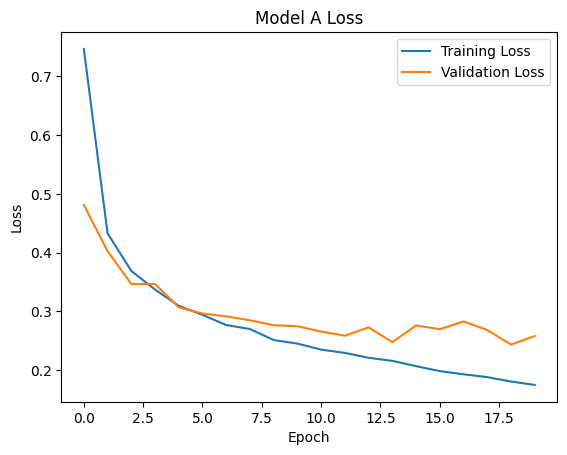

In [20]:
plt.plot(history_a.history["loss"], label="Training Loss")
plt.plot(history_a.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Loss")
plt.legend()
plt.show()

## 21. Model B Loss

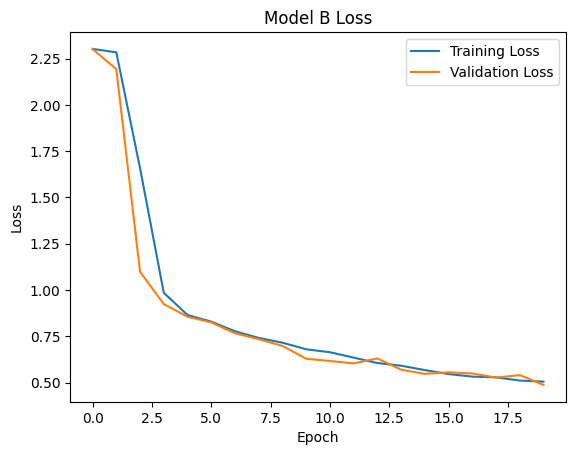

In [21]:
plt.plot(history_b.history["loss"], label="Training Loss")
plt.plot(history_b.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Loss")
plt.legend()
plt.show()

# Model Evaluation

## 22. Evaluate Model A

We calculate:

- Accuracy
- Precision
- Recall
- Confusion matrix

In [22]:
prob_a = model_a.predict(x_test, verbose=0)
pred_a = np.argmax(prob_a, axis=1)

accuracy_a = accuracy_score(y_test, pred_a)
precision_a = precision_score(y_test, pred_a, average="weighted", zero_division=0)
recall_a = recall_score(y_test, pred_a, average="weighted", zero_division=0)

print("Accuracy:", accuracy_a)
print("Precision:", precision_a)
print("Recall:", recall_a)

Accuracy: 0.9081904761904762
Precision: 0.9095512420855433
Recall: 0.9081904761904762


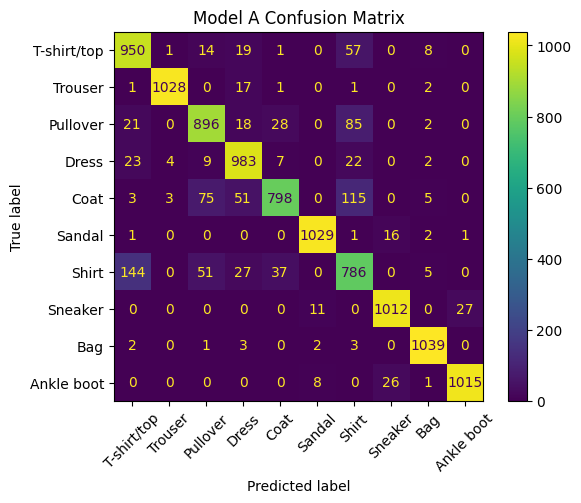

In [23]:
cm_a = confusion_matrix(y_test, pred_a)

display_a = ConfusionMatrixDisplay(
    confusion_matrix=cm_a,
    display_labels=class_names
)

display_a.plot(xticks_rotation=45)
plt.title("Model A Confusion Matrix")
plt.show()

In [24]:
print(classification_report(
    y_test,
    pred_a,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.90      0.87      1050
     Trouser       0.99      0.98      0.99      1050
    Pullover       0.86      0.85      0.85      1050
       Dress       0.88      0.94      0.91      1050
        Coat       0.92      0.76      0.83      1050
      Sandal       0.98      0.98      0.98      1050
       Shirt       0.73      0.75      0.74      1050
     Sneaker       0.96      0.96      0.96      1050
         Bag       0.97      0.99      0.98      1050
  Ankle boot       0.97      0.97      0.97      1050

    accuracy                           0.91     10500
   macro avg       0.91      0.91      0.91     10500
weighted avg       0.91      0.91      0.91     10500



## 23. Evaluate Model B

In [25]:
prob_b = model_b.predict(x_test, verbose=0)
pred_b = np.argmax(prob_b, axis=1)

accuracy_b = accuracy_score(y_test, pred_b)
precision_b = precision_score(y_test, pred_b, average="weighted", zero_division=0)
recall_b = recall_score(y_test, pred_b, average="weighted", zero_division=0)

print("Accuracy:", accuracy_b)
print("Precision:", precision_b)
print("Recall:", recall_b)

Accuracy: 0.8176190476190476
Precision: 0.8180088789725682
Recall: 0.8176190476190476


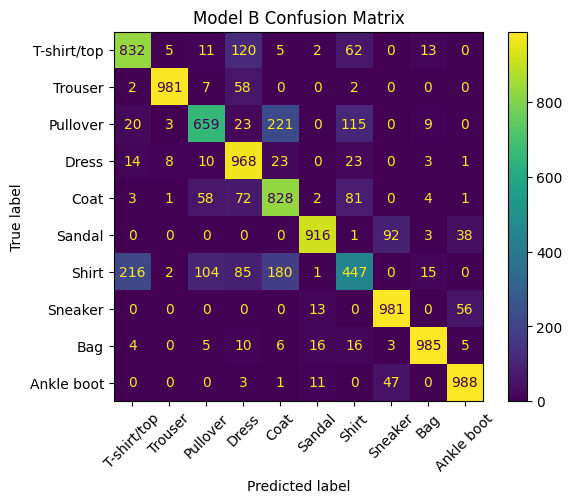

In [26]:
cm_b = confusion_matrix(y_test, pred_b)

display_b = ConfusionMatrixDisplay(
    confusion_matrix=cm_b,
    display_labels=class_names
)

display_b.plot(xticks_rotation=45)
plt.title("Model B Confusion Matrix")
plt.show()

In [27]:
print(classification_report(
    y_test,
    pred_b,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.76      0.79      0.78      1050
     Trouser       0.98      0.93      0.96      1050
    Pullover       0.77      0.63      0.69      1050
       Dress       0.72      0.92      0.81      1050
        Coat       0.66      0.79      0.72      1050
      Sandal       0.95      0.87      0.91      1050
       Shirt       0.60      0.43      0.50      1050
     Sneaker       0.87      0.93      0.90      1050
         Bag       0.95      0.94      0.95      1050
  Ankle boot       0.91      0.94      0.92      1050

    accuracy                           0.82     10500
   macro avg       0.82      0.82      0.81     10500
weighted avg       0.82      0.82      0.81     10500



# Model Size

## 24. Save Models and Measure Disk Size

We save each model as a `.keras` archive and measure its size in KiB or MiB. These archives include optimizer state. Their size is not equivalent to peak RAM or deployment inference memory.

In [28]:
model_a.save("model_a_revised.keras")
model_b.save("model_b_revised.keras")

size_a = os.path.getsize("model_a_revised.keras") / 1024
size_b = os.path.getsize("model_b_revised.keras") / 1024

print("Model A size:", size_a, "KiB")
print("Model B size:", size_b, "KiB")

Model A size: 861.1796875 KiB
Model B size: 83.7666015625 KiB


# Custom Model Comparison

## 25. Compare Model A and Model B

In [29]:
custom_results = pd.DataFrame({
    "Model": ["Model A", "Model B"],
    "Parameters": [
        model_a.count_params(),
        model_b.count_params()
    ],
    "Model Size (KiB)": [
        size_a,
        size_b
    ],
    "Time per Epoch (s)": [
        time_per_epoch_a,
        time_per_epoch_b
    ],
    "Test Accuracy": [
        accuracy_a,
        accuracy_b
    ],
    "Precision": [
        precision_a,
        precision_b
    ],
    "Recall": [
        recall_a,
        recall_b
    ]
})

custom_results

,Model,Parameters,Model Size (KiB),Time per Epoch (s),Test Accuracy,Precision,Recall
0,Model A,105866,861.179688,3.325511,0.908190,0.909551,0.908190
1,Model B,5539,83.766602,3.920353,0.817619,0.818009,0.817619


# Lightweight Pre-trained Networks

We compare Model B with ImageNet-pretrained MobileNetV2 and EfficientNetB0.

The custom models use normalized $28 \times 28$ grayscale images. The pretrained models use resized $64 \times 64$ RGB images from the same training, validation and test partitions.

## 26. Prepare Data for Pre-trained Models

We resize images to $64 \times 64$ and repeat the grayscale channel to create RGB input, keeping pixel values in [0,255].

MobileNetV2 uses its own preprocessing function. EfficientNetB0 accepts [0,255] inputs through its built-in preprocessing.

In [30]:
def prepare_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, axis=-1)
    image = tf.image.resize(image, (64, 64))
    image = tf.image.grayscale_to_rgb(image)

    return image, label

In [31]:
train_data = tf.data.Dataset.from_tensor_slices((x_train_raw, y_train))
val_data = tf.data.Dataset.from_tensor_slices((x_val_raw, y_val))
test_data = tf.data.Dataset.from_tensor_slices((x_test_raw, y_test))

train_data = train_data.map(prepare_image).shuffle(10000, seed=SEED, reshuffle_each_iteration=True).batch(128).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(prepare_image).batch(128).prefetch(tf.data.AUTOTUNE)

# MobileNetV2

## 27. Build MobileNetV2

We remove the original ImageNet classifier and add our own 10-class output layer.

In [32]:
reset_randomness()
mobile_base = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

mobile_base.trainable = False

mobile_input = keras.Input(shape=(64, 64, 3))

x = keras.applications.mobilenet_v2.preprocess_input(mobile_input)
x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)

mobile_output = layers.Dense(10, activation="softmax")(x)

mobile_model = keras.Model(mobile_input, mobile_output)

mobile_model.summary()

/tmp/ipykernel_1296/274062916.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobile_base = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 28. Train MobileNetV2 - Frozen Base

First we train only the new output layer for 5 epochs.

In [33]:
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

Epoch 1/5
383/383 - 19s - 49ms/step - accuracy: 0.7873 - loss: 0.6251 - val_accuracy: 0.8516 - val_loss: 0.4459
Epoch 2/5
383/383 - 13s - 33ms/step - accuracy: 0.8538 - loss: 0.4121 - val_accuracy: 0.8598 - val_loss: 0.4112
Epoch 3/5
383/383 - 13s - 33ms/step - accuracy: 0.8669 - loss: 0.3706 - val_accuracy: 0.8590 - val_loss: 0.4088
Epoch 4/5
383/383 - 20s - 53ms/step - accuracy: 0.8745 - loss: 0.3471 - val_accuracy: 0.8628 - val_loss: 0.4015
Epoch 5/5
383/383 - 13s - 33ms/step - accuracy: 0.8801 - loss: 0.3339 - val_accuracy: 0.8631 - val_loss: 0.3985


## 29. Fine-tune MobileNetV2

After five frozen-backbone epochs, we unfreeze the last 20 backbone layers and fine-tune for 15 epochs using learning rate 0.00001. The backbone is called with `training=False` to keep batch-normalization statistics fixed.

In [34]:
mobile_base.trainable = True

for layer in mobile_base.layers[:-20]:
    layer.trainable = False

mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

mobile_history = mobile_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

mobile_time = time.time() - start

Epoch 1/15
383/383 - 25s - 65ms/step - accuracy: 0.7485 - loss: 0.8153 - val_accuracy: 0.8598 - val_loss: 0.4273
Epoch 2/15
383/383 - 16s - 43ms/step - accuracy: 0.8287 - loss: 0.5124 - val_accuracy: 0.8538 - val_loss: 0.4542
Epoch 3/15
383/383 - 17s - 44ms/step - accuracy: 0.8519 - loss: 0.4266 - val_accuracy: 0.8557 - val_loss: 0.4582
Epoch 4/15
383/383 - 16s - 42ms/step - accuracy: 0.8688 - loss: 0.3708 - val_accuracy: 0.8608 - val_loss: 0.4406
Epoch 5/15
383/383 - 16s - 42ms/step - accuracy: 0.8816 - loss: 0.3338 - val_accuracy: 0.8660 - val_loss: 0.4182
Epoch 6/15
383/383 - 16s - 42ms/step - accuracy: 0.8925 - loss: 0.3002 - val_accuracy: 0.8671 - val_loss: 0.4061
Epoch 7/15
383/383 - 17s - 43ms/step - accuracy: 0.8995 - loss: 0.2787 - val_accuracy: 0.8705 - val_loss: 0.3911
Epoch 8/15
383/383 - 16s - 42ms/step - accuracy: 0.9088 - loss: 0.2526 - val_accuracy: 0.8724 - val_loss: 0.3856
Epoch 9/15
383/383 - 16s - 42ms/step - accuracy: 0.9154 - loss: 0.2332 - val_accuracy: 0.8751 - 

## 30. Evaluate MobileNetV2

Accuracy: 0.8799047470092773
Precision: 0.8801718654886916
Recall: 0.8799047619047619
Parameters: 2270794


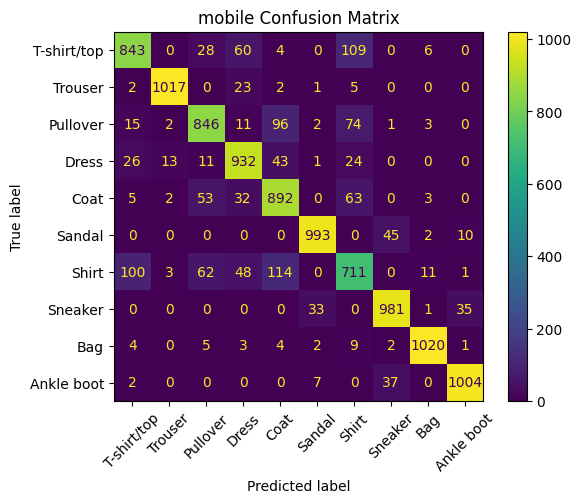

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.80      0.82      1050
     Trouser       0.98      0.97      0.97      1050
    Pullover       0.84      0.81      0.82      1050
       Dress       0.84      0.89      0.86      1050
        Coat       0.77      0.85      0.81      1050
      Sandal       0.96      0.95      0.95      1050
       Shirt       0.71      0.68      0.70      1050
     Sneaker       0.92      0.93      0.93      1050
         Bag       0.98      0.97      0.97      1050
  Ankle boot       0.96      0.96      0.96      1050

    accuracy                           0.88     10500
   macro avg       0.88      0.88      0.88     10500
weighted avg       0.88      0.88      0.88     10500



In [35]:
mobile_loss, mobile_accuracy = mobile_model.evaluate(test_data, verbose=0)

mobile_pred_prob = mobile_model.predict(test_data, verbose=0)
mobile_pred = np.argmax(mobile_pred_prob, axis=1)

mobile_precision = precision_score(y_test, mobile_pred, average="weighted", zero_division=0)
mobile_recall = recall_score(y_test, mobile_pred, average="weighted", zero_division=0)

print("Accuracy:", mobile_accuracy)
print("Precision:", mobile_precision)
print("Recall:", mobile_recall)
print("Parameters:", mobile_model.count_params())

mobile_cm = confusion_matrix(y_test, mobile_pred, labels=np.arange(10))
ConfusionMatrixDisplay(mobile_cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title("mobile Confusion Matrix")
plt.show()
print(classification_report(y_test, mobile_pred, target_names=class_names, zero_division=0))

In [36]:
mobile_model.save("mobilenetv2_revised.keras")
mobile_size = os.path.getsize("mobilenetv2_revised.keras") / (1024 * 1024)

print("MobileNetV2 size:", mobile_size, "MiB")

MobileNetV2 size: 18.535822868347168 MiB


# EfficientNetB0

## 31. Build EfficientNetB0

In [37]:
reset_randomness()
efficient_base = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(64, 64, 3)
)

efficient_base.trainable = False

efficient_input = keras.Input(shape=(64, 64, 3))

x = efficient_base(efficient_input, training=False)
x = layers.GlobalAveragePooling2D()(x)

efficient_output = layers.Dense(10, activation="softmax")(x)

efficient_model = keras.Model(efficient_input, efficient_output)

efficient_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 32. Train EfficientNetB0 - Frozen Base

We freeze the backbone and train the new output layer for five epochs.

In [38]:
efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=2
)

Epoch 1/5
383/383 - 27s - 71ms/step - accuracy: 0.7969 - loss: 0.6130 - val_accuracy: 0.8580 - val_loss: 0.4095
Epoch 2/5
383/383 - 17s - 45ms/step - accuracy: 0.8555 - loss: 0.4092 - val_accuracy: 0.8702 - val_loss: 0.3638
Epoch 3/5
383/383 - 15s - 40ms/step - accuracy: 0.8661 - loss: 0.3744 - val_accuracy: 0.8761 - val_loss: 0.3458
Epoch 4/5
383/383 - 15s - 39ms/step - accuracy: 0.8717 - loss: 0.3556 - val_accuracy: 0.8783 - val_loss: 0.3360
Epoch 5/5
383/383 - 15s - 40ms/step - accuracy: 0.8770 - loss: 0.3407 - val_accuracy: 0.8822 - val_loss: 0.3254


## 33. Fine-tune EfficientNetB0

We then unfreeze the last 20 backbone layers and fine-tune for 15 epochs using learning rate 0.00001. As with MobileNetV2, batch-normalization statistics remain fixed.

In [39]:
efficient_base.trainable = True

for layer in efficient_base.layers[:-20]:
    layer.trainable = False

efficient_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

efficient_history = efficient_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    verbose=2
)

efficient_time = time.time() - start

Epoch 1/15
383/383 - 31s - 81ms/step - accuracy: 0.7742 - loss: 0.6769 - val_accuracy: 0.8408 - val_loss: 0.4814
Epoch 2/15
383/383 - 17s - 44ms/step - accuracy: 0.8275 - loss: 0.5083 - val_accuracy: 0.8565 - val_loss: 0.4346
Epoch 3/15
383/383 - 17s - 45ms/step - accuracy: 0.8478 - loss: 0.4468 - val_accuracy: 0.8666 - val_loss: 0.4034
Epoch 4/15
383/383 - 17s - 44ms/step - accuracy: 0.8567 - loss: 0.4155 - val_accuracy: 0.8722 - val_loss: 0.3820
Epoch 5/15
383/383 - 17s - 45ms/step - accuracy: 0.8634 - loss: 0.3907 - val_accuracy: 0.8765 - val_loss: 0.3665
Epoch 6/15
383/383 - 20s - 53ms/step - accuracy: 0.8699 - loss: 0.3722 - val_accuracy: 0.8808 - val_loss: 0.3546
Epoch 7/15
383/383 - 17s - 44ms/step - accuracy: 0.8756 - loss: 0.3520 - val_accuracy: 0.8836 - val_loss: 0.3448
Epoch 8/15
383/383 - 17s - 44ms/step - accuracy: 0.8765 - loss: 0.3423 - val_accuracy: 0.8867 - val_loss: 0.3364
Epoch 9/15
383/383 - 21s - 54ms/step - accuracy: 0.8825 - loss: 0.3311 - val_accuracy: 0.8879 - 

## 34. Evaluate EfficientNetB0

Accuracy: 0.8926666378974915
Precision: 0.8927181597794371
Recall: 0.8926666666666667
Parameters: 4062381


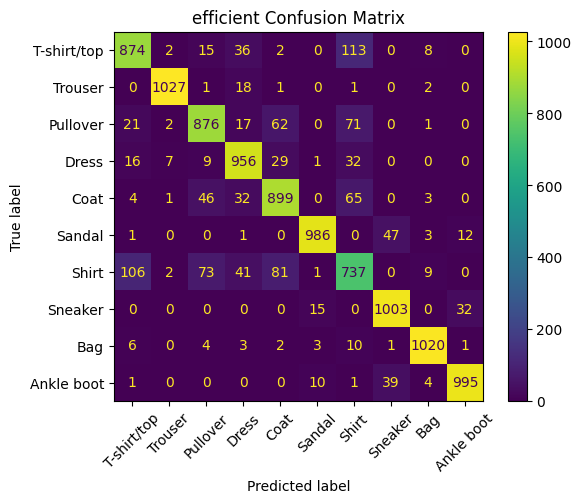

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.83      0.84      1050
     Trouser       0.99      0.98      0.98      1050
    Pullover       0.86      0.83      0.84      1050
       Dress       0.87      0.91      0.89      1050
        Coat       0.84      0.86      0.85      1050
      Sandal       0.97      0.94      0.95      1050
       Shirt       0.72      0.70      0.71      1050
     Sneaker       0.92      0.96      0.94      1050
         Bag       0.97      0.97      0.97      1050
  Ankle boot       0.96      0.95      0.95      1050

    accuracy                           0.89     10500
   macro avg       0.89      0.89      0.89     10500
weighted avg       0.89      0.89      0.89     10500



In [40]:
efficient_loss, efficient_accuracy = efficient_model.evaluate(test_data, verbose=0)

efficient_pred_prob = efficient_model.predict(test_data, verbose=0)
efficient_pred = np.argmax(efficient_pred_prob, axis=1)

efficient_precision = precision_score(y_test, efficient_pred, average="weighted", zero_division=0)
efficient_recall = recall_score(y_test, efficient_pred, average="weighted", zero_division=0)

print("Accuracy:", efficient_accuracy)
print("Precision:", efficient_precision)
print("Recall:", efficient_recall)
print("Parameters:", efficient_model.count_params())

efficient_cm = confusion_matrix(y_test, efficient_pred, labels=np.arange(10))
ConfusionMatrixDisplay(efficient_cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title("efficient Confusion Matrix")
plt.show()
print(classification_report(y_test, efficient_pred, target_names=class_names, zero_division=0))

In [41]:
efficient_model.save("efficientnetb0_revised.keras")
efficient_size = os.path.getsize("efficientnetb0_revised.keras") / (1024 * 1024)

print("EfficientNetB0 size:", efficient_size, "MiB")

EfficientNetB0 size: 26.71912670135498 MiB


# Final Comparison

## 35. Accuracy, Disk Storage and Analytical Computational Cost

One multiply-accumulate counts as one MAC. We estimate convolution and dense-layer kernel MACs per image at each model's input resolution.

- Standard convolution: $H_{\mathrm{out}} \times W_{\mathrm{out}} \times K_h \times K_w \times C_{\mathrm{in}} \times C_{\mathrm{out}} / \mathrm{groups}$
- Separable convolution (depth multiplier 1): $H_{\mathrm{out}} \times W_{\mathrm{out}} \times (K_h \times K_w \times C_{\mathrm{in}} + C_{\mathrm{in}} \times C_{\mathrm{out}})$
- Model A: $112896 + 903168 + 100352 + 640 = 1,117,056 \mathrm{MACs/image}$
- Model B: $19600 + 128576 + 114464 + 2048 + 320 = 265,008 \mathrm{MACs/image}$

These estimates exclude bias additions, activations, pooling, normalization, residual additions, elementwise scaling and preprocessing. They are analytical kernel costs, not measured latency.

Precision and recall are support-weighted. Per-class reports and confusion matrices are shown above. Custom inputs are $28 \times 28$ grayscale; pretrained inputs are $64 \times 64$ RGB.

In [42]:
def analytical_macs(model):
    total = 0
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            total += analytical_macs(layer)
            continue
        if not isinstance(layer, (layers.Conv2D, layers.DepthwiseConv2D,
                                  layers.SeparableConv2D, layers.Dense)):
            continue
        shape = tuple(layer.output.shape)
        if any(d is None for d in shape[1:]):
            raise ValueError("Static dimensions required: " + layer.name)
        if isinstance(layer, layers.Dense):
            total += int(np.prod(shape[1:-1])) * int(layer.kernel.shape[0]) * int(layer.units)
            continue
        positions = int(np.prod(shape[1:3]))
        kh, kw = layer.kernel_size
        cin = int(layer.input.shape[-1])
        if isinstance(layer, layers.SeparableConv2D):
            total += positions * (kh * kw * cin * layer.depth_multiplier
                                  + cin * layer.depth_multiplier * layer.filters)
        elif isinstance(layer, layers.DepthwiseConv2D):
            total += positions * kh * kw * cin * layer.depth_multiplier
        else:
            total += positions * kh * kw * cin * layer.filters // layer.groups
    return int(total)

mac_a = analytical_macs(model_a)
mac_b = analytical_macs(model_b)
assert mac_a == 1117056
assert mac_b == 265008
mobile_macs = analytical_macs(mobile_model)
efficient_macs = analytical_macs(efficient_model)

final_results = pd.DataFrame({
    "Model": ["Model A", "Model B", "MobileNetV2", "EfficientNetB0"],
    "Parameters": [m.count_params() for m in [model_a, model_b, mobile_model, efficient_model]],
    "Archive Size (MiB)": [size_a / 1024, size_b / 1024, mobile_size, efficient_size],
    "Average Fit Epoch (s)": [time_per_epoch_a, time_per_epoch_b, np.nan, np.nan],
    "Test Accuracy": [accuracy_a, accuracy_b, mobile_accuracy, efficient_accuracy],
    "Weighted Precision": [precision_a, precision_b, mobile_precision, efficient_precision],
    "Weighted Recall": [recall_a, recall_b, mobile_recall, efficient_recall],
    "Kernel MACs/image": [mac_a, mac_b, mobile_macs, efficient_macs]
})
print("SOTA epoch timing is not benchmarked; NaN means not reported.")
print("All four confusion matrices and per-class metrics appear above.")
final_results

SOTA epoch timing is not benchmarked; NaN means not reported.
All four confusion matrices and per-class metrics appear above.


,Model,Parameters,Archive Size (MiB),Average Fit Epoch (s),Test Accuracy,Weighted Precision,Weighted Recall,Kernel MACs/image
0,Model A,105866,0.840996,3.325511,0.908190,0.909551,0.908190,1117056
1,Model B,5539,0.081803,3.920353,0.817619,0.818009,0.817619,265008
2,MobileNetV2,2270794,18.535823,NaN,0.879905,0.880172,0.879905,24461312
3,EfficientNetB0,4062381,26.719127,NaN,0.892667,0.892718,0.892667,31979392


## Interpretation

Model A achieves 90.82% test accuracy with 105,866 parameters. Model B achieves 81.76% with only 5,539 parameters. Its analytical kernel MACs fall from 1,117,056 to 265,008 per image, about 76.3% fewer.

Model B also has lower saved storage: about 0.082 MiB compared with Model A's 0.841 MiB. However, its average training time per epoch is higher: 3.92 s compared with 3.33 s. Fewer MACs do not guarantee faster training because hardware and operation implementations also affect execution time. These times include validation and initial startup overhead.

MobileNetV2 reaches 87.99% test accuracy and EfficientNetB0 reaches 89.27%. Both outperform Model B but require substantially more parameters and storage. They also benefit from features learned on ImageNet. The pretrained models use $64 \times 64$ RGB inputs, while the custom models use $28 \times 28$ grayscale inputs, so input resolution also affects computational cost.

Saved `.keras` archive sizes include optimizer state and do not measure peak RAM or deployment inference memory.